# Prediksi Harga Rumah dengan Regresi Linear

## 1. Import Library
Kita menggunakan `pandas` dan `numpy` untuk pengolahan data, `matplotlib`/`seaborn` untuk visualisasi, dan `scikit-learn` untuk membangun model machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
%matplotlib inline


## 2. Load Dataset
Dataset disimpan dalam file `USA_Housing.csv`. Kita load menggunakan `pandas.read_csv()`.

In [2]:
df = pd.read_csv('USA_Housing.csv')
df.head()


,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


**Keterangan kolom:**
- `Avg. Area Income` : Rata-rata pendapatan penduduk di area tersebut
- `Avg. Area House Age` : Rata-rata usia rumah di area tersebut
- `Avg. Area Number of Rooms` : Rata-rata jumlah ruangan rumah
- `Avg. Area Number of Bedrooms` : Rata-rata jumlah kamar tidur
- `Area Population` : Jumlah populasi di area tersebut
- `Price` : Harga rumah 
- `Address` : Alamat rumah (tidak digunakan untuk pemodelan, hanya teks)


In [3]:
# Melihat ukuran data (jumlah baris dan kolom)
print('Jumlah baris dan kolom:', df.shape)


Jumlah baris dan kolom: (5000, 7)


In [4]:
# Informasi tipe data dan jumlah data non-null
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   str    
dtypes: float64(6), str(1)
memory usage: 273.6 KB


In [5]:
# Cek apakah ada data yang kosong (missing value)
df.isnull().sum()


Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

Tidak ada data yang kosong, sehingga kita tidak perlu melakukan proses pembersihan data (data cleaning) untuk missing value.

In [6]:
# Statistik deskriptif dari data numerik (mean, std, min, max, dll)
df.describe()


,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


## 3. Eksplorasi & Visualisasi Data (EDA)
Tahap ini bertujuan untuk memahami pola dan hubungan antar variabel sebelum membangun model.

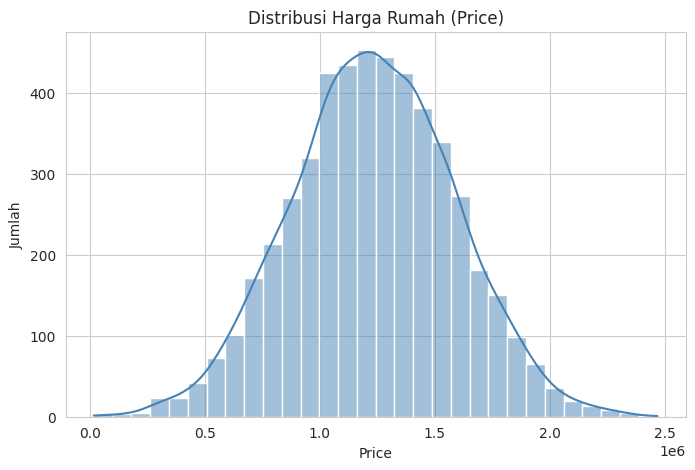

In [7]:
# Distribusi variabel target (Price)
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True, bins=30, color='steelblue')
plt.title('Distribusi Harga Rumah (Price)')
plt.xlabel('Price')
plt.ylabel('Jumlah')
plt.show()


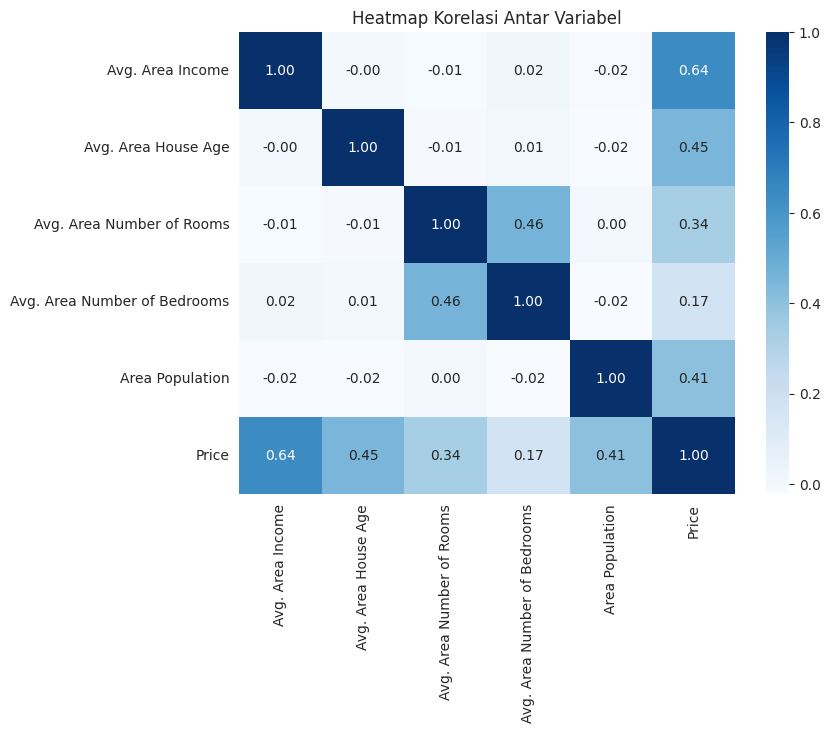

In [8]:
# Melihat korelasi antar variabel numerik
plt.figure(figsize=(8,6))
corr = df.drop(columns=['Address']).corr()
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')
plt.title('Heatmap Korelasi Antar Variabel')
plt.show()


**Insight dari heatmap korelasi:**
Kita bisa melihat fitur mana yang paling berkorelasi (berhubungan kuat) dengan `Price`. Semakin mendekati nilai 1, semakin kuat hubungan positifnya. Biasanya `Avg. Area Income` memiliki korelasi paling tinggi terhadap `Price`.

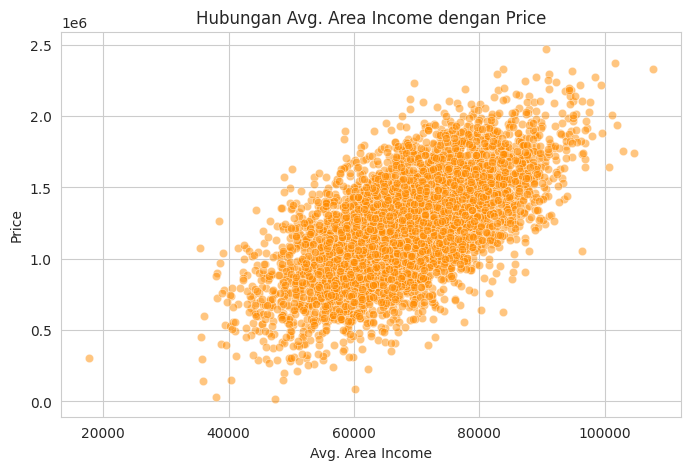

In [9]:
# Scatter plot hubungan antara Avg. Area Income dengan Price
plt.figure(figsize=(8,5))
sns.scatterplot(x='Avg. Area Income', y='Price', data=df, alpha=0.5, color='darkorange')
plt.title('Hubungan Avg. Area Income dengan Price')
plt.show()


## 4. Preprocessing Data

In [10]:
X = df.drop(columns=['Price', 'Address'])
y = df['Price']

print('Fitur (X):', list(X.columns))
print('Target (y): Price')


Fitur (X): ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population']
Target (y): Price


## 5. Split Data (Train & Test)
Data dibagi menjadi data latih (*training*) untuk melatih model, dan data uji (*testing*) untuk mengevaluasi performa model terhadap data yang belum pernah dilihat model.

Kita menggunakan pembagian 80% data latih dan 20% data uji.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Jumlah data latih:', X_train.shape[0])
print('Jumlah data uji  :', X_test.shape[0])


Jumlah data latih: 4000
Jumlah data uji  : 1000


## 6. Membangun Model Regresi Linear
Kita menggunakan algoritma **Linear Regression** dari `scikit-learn`. Model ini akan mencari hubungan linear terbaik antara fitur (X) dan target (y) yaitu `Price`.

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Model berhasil dilatih (trained).')


Model berhasil dilatih (trained).


In [13]:
# Melihat koefisien (bobot) setiap fitur terhadap Price
coefficients = pd.DataFrame(model.coef_, X.columns, columns=['Koefisien'])
coefficients


,Koefisien
Avg. Area Income,21.652206
Avg. Area House Age,164666.480722
Avg. Area Number of Rooms,119624.012232
Avg. Area Number of Bedrooms,2440.377611
Area Population,15.270313


**Interpretasi koefisien:**
Setiap nilai koefisien menunjukkan seberapa besar pengaruh kenaikan 1 unit fitur tersebut terhadap `Price`, dengan asumsi fitur lain tetap (konstan). Misalnya, jika koefisien `Avg. Area Income` bernilai positif besar, artinya semakin tinggi pendapatan rata-rata area, semakin tinggi pula harga rumah.

## 7. Prediksi dan Evaluasi Model
Setelah model dilatih, kita gunakan untuk memprediksi data uji (`X_test`), lalu bandingkan hasil prediksi dengan nilai sebenarnya (`y_test`).

In [14]:
y_pred = model.predict(X_test)

# Membandingkan beberapa nilai aktual vs prediksi
hasil = pd.DataFrame({'Harga Aktual': y_test.values, 'Harga Prediksi': y_pred})
hasil.head(10)


,Harga Aktual,Harga Prediksi
0,1.339096e+06,1.308588e+06
1,1.251794e+06,1.237037e+06
2,1.340095e+06,1.243429e+06
3,1.431508e+06,1.228900e+06
4,1.042374e+06,1.063321e+06
5,1.555321e+06,1.544058e+06
6,1.250882e+06,1.094775e+06
7,1.039381e+06,8.332847e+05
8,8.324752e+05,7.884129e+05
9,1.420648e+06,1.469715e+06


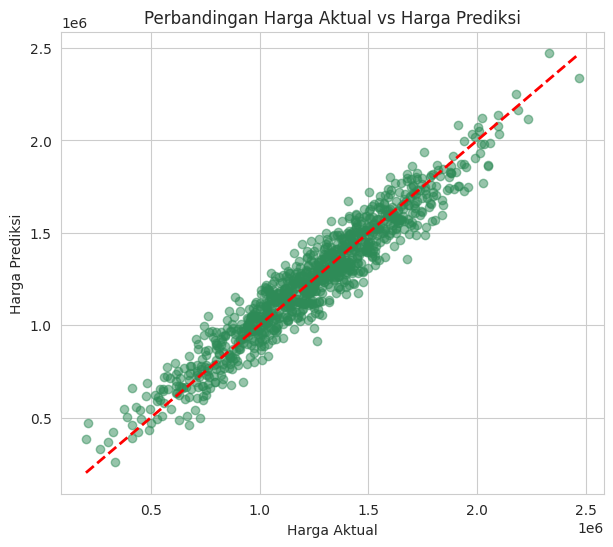

In [15]:
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='seagreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Perbandingan Harga Aktual vs Harga Prediksi')
plt.show()


Garis merah putus-putus menunjukkan kondisi ideal (prediksi = aktual). Semakin titik-titik berada dekat dengan garis tersebut, semakin baik prediksi model.

In [16]:
mae_lr = mean_absolute_error(y_test, y_pred)
mse_lr = mean_squared_error(y_test, y_pred)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred)

print(f'MAE  (Mean Absolute Error)      : {mae_lr:,.2f}')
print(f'MSE  (Mean Squared Error)       : {mse_lr:,.2f}')
print(f'RMSE (Root Mean Squared Error)  : {rmse_lr:,.2f}')
print(f'R2 Score                        : {r2_lr:.4f}')


MAE  (Mean Absolute Error)      : 80,879.10
MSE  (Mean Squared Error)       : 10,089,009,300.89
RMSE (Root Mean Squared Error)  : 100,444.06
R2 Score                        : 0.9180


**Penjelasan metrik evaluasi (penting saat presentasi ke penguji):**
- **MAE**: rata-rata selisih absolut antara prediksi dan nilai aktual. Semakin kecil, semakin baik.
- **MSE/RMSE**: mirip MAE tapi memberi penalti lebih besar untuk error yang besar. RMSE memiliki satuan yang sama dengan `Price`, sehingga lebih mudah diinterpretasikan.
- **R2 Score**: menunjukkan seberapa besar persentase variasi `Price` yang bisa dijelaskan oleh model (skala 0–1). Semakin mendekati 1, semakin baik model dalam menjelaskan data.


## 8. Model Pembanding: Random Forest Regressor
Selain Regresi Linear, kita coba bandingkan dengan **Random Forest Regressor** — model berbasis kumpulan banyak *decision tree* (disebut *ensemble*).

**Kelebihan Random Forest dibanding Regresi Linear:**
- Bisa menangkap hubungan **non-linear** antar fitur dan target.
- Lebih tahan terhadap outlier.
- Biasanya akurasi lebih tinggi pada data yang kompleks.

**Kekurangannya:**
- Lebih sulit diinterpretasikan (tidak ada koefisien sederhana seperti regresi linear).
- Proses training lebih berat secara komputasi.

Kita menggunakan data latih dan data uji **yang sama persis** seperti sebelumnya (`X_train`, `X_test`, `y_train`, `y_test`), agar perbandingan antar model adil (*apple-to-apple*).

In [17]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f'MAE  (Mean Absolute Error)      : {mae_rf:,.2f}')
print(f'MSE  (Mean Squared Error)       : {mse_rf:,.2f}')
print(f'RMSE (Root Mean Squared Error)  : {rmse_rf:,.2f}')
print(f'R2 Score                        : {r2_rf:.4f}')


MAE  (Mean Absolute Error)      : 94,672.47
MSE  (Mean Squared Error)       : 14,465,132,338.70
RMSE (Root Mean Squared Error)  : 120,271.08
R2 Score                        : 0.8824


In [18]:
# Tabel perbandingan kedua model
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regressor'],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R2 Score': [r2_lr, r2_rf]
})
comparison


,Model,MAE,RMSE,R2 Score
0,Linear Regression,80879.097235,100444.060556,0.917997
1,Random Forest Regressor,94672.466511,120271.078563,0.882428


/tmp/ipykernel_528/3692631654.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='R2 Score', data=comparison, palette=['steelblue', 'seagreen'])


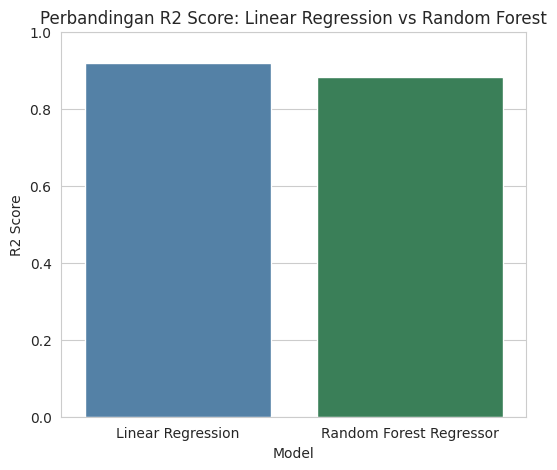

In [19]:
# Visualisasi perbandingan R2 Score kedua model
plt.figure(figsize=(6,5))
sns.barplot(x='Model', y='R2 Score', data=comparison, palette=['steelblue', 'seagreen'])
plt.title('Perbandingan R2 Score: Linear Regression vs Random Forest')
plt.ylim(0, 1)
plt.show()


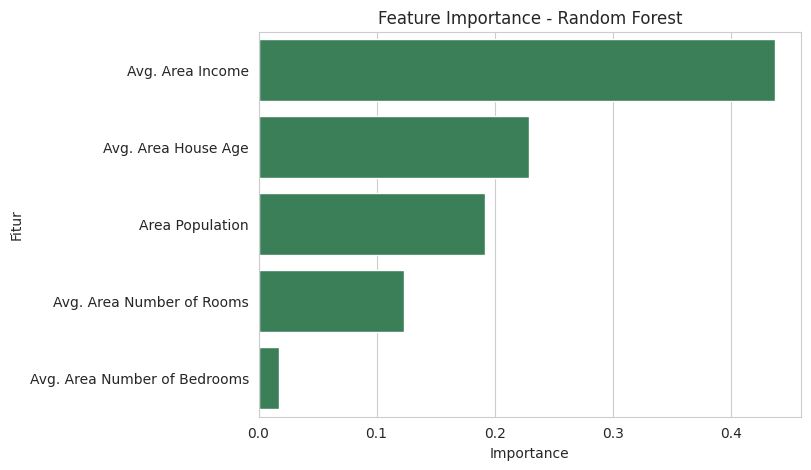

In [20]:
# Feature importance dari Random Forest
importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(7,5))
sns.barplot(x='Importance', y='Fitur', data=importance, color='seagreen')
plt.title('Feature Importance - Random Forest')
plt.show()


**Interpretasi feature importance:**
Grafik ini menunjukkan fitur mana yang paling berpengaruh menurut Random Forest dalam memprediksi `Price`. Berbeda dengan koefisien regresi linear, nilai importance ini tidak menunjukkan arah (positif/negatif), hanya menunjukkan seberapa besar pengaruhnya.

## 9. Feature Engineering: Ekstrak `State` dari `Address`
Sebelumnya kolom `Address` tidak dipakai karena isinya teks alamat yang hampir semua unik (tidak bisa langsung diubah jadi angka yang bermakna).

Tapi kita bisa mengekstrak informasi yang berguna dari teks tersebut, yaitu kode State (negara bagian, contoh: `NE`, `CA`, `TX`). State ini berulang di banyak baris, sehingga cocok diubah menjadi angka menggunakan One-Hot Encoding.

Format alamat: `Jalan, Apt\nKota, STATE ZIPCODE` — kita ambil bagian STATE-nya menggunakan regex.

In [21]:
import re

def extract_state(address):
    # Cari pola 2 huruf kapital sebelum kode pos (format umum US: "City, ST 12345")
    match = re.search(r',\s*([A-Z]{2})\s+\d{5}', address)
    return match.group(1) if match else None

df['State'] = df['Address'].apply(extract_state)

print('Jumlah State unik:', df['State'].nunique())
df[['Address', 'State']].head()


Jumlah State unik: 59


,Address,State
0,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701...",NE
1,"188 Johnson Views Suite 079\nLake Kathleen, CA...",CA
2,"9127 Elizabeth Stravenue\nDanieltown, WI 06482...",WI
3,USS Barnett\nFPO AP 44820,NaN
4,USNS Raymond\nFPO AE 09386,NaN


In [22]:
# Cek apakah ada alamat yang gagal diekstrak State-nya
print('Jumlah data tanpa State (gagal ekstraksi):', df['State'].isnull().sum())


Jumlah data tanpa State (gagal ekstraksi): 514


In [23]:
# Lihat distribusi jumlah rumah per State (top 10)
df['State'].value_counts().head(10)


State
OR    91
GU    91
DE    89
KY    89
NC    89
AZ    86
VT    86
VA    85
NE    84
ND    84
Name: count, dtype: int64

**Catatan:** State tersebar cukup merata (karena data ini sintetis), jadi secara realistis State mungkin tidak terlalu menambah informasi prediktif untuk dataset ini. Tapi kita tetap coba untuk membuktikan apakah dugaan ini benar lewat data, bukan asumsi.

In [24]:
# One-Hot Encoding untuk kolom State
state_encoded = pd.get_dummies(df['State'], prefix='State', drop_first=True)

print('Jumlah kolom baru hasil One-Hot Encoding:', state_encoded.shape[1])
state_encoded.head()


Jumlah kolom baru hasil One-Hot Encoding: 58


,State_AL,State_AR,State_AS,State_AZ,State_CA,State_CO,State_CT,State_DC,State_DE,State_FL,...,State_TN,State_TX,State_UT,State_VA,State_VI,State_VT,State_WA,State_WI,State_WV,State_WY
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [25]:
# Gabungkan fitur asli dengan fitur State hasil encoding
X_with_state = pd.concat([df.drop(columns=['Price', 'Address', 'State']), state_encoded], axis=1)
y_with_state = df['Price']

print('Jumlah fitur sebelum tambah State:', X.shape[1])
print('Jumlah fitur setelah tambah State :', X_with_state.shape[1])


Jumlah fitur sebelum tambah State: 5
Jumlah fitur setelah tambah State : 63


## 10. Latih Ulang Model dengan Fitur Tambahan `State`
Kita gunakan `random_state` yang sama agar split data identik dengan sebelumnya, supaya perbandingan adil (*apple-to-apple*).

In [26]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_with_state, y_with_state, test_size=0.2, random_state=42
)

# Linear Regression dengan fitur tambahan State
model_state = LinearRegression()
model_state.fit(X_train2, y_train2)
y_pred_state = model_state.predict(X_test2)

mae_state = mean_absolute_error(y_test2, y_pred_state)
rmse_state = np.sqrt(mean_squared_error(y_test2, y_pred_state))
r2_state = r2_score(y_test2, y_pred_state)

print(f'MAE  : {mae_state:,.2f}')
print(f'RMSE : {rmse_state:,.2f}')
print(f'R2   : {r2_state:.4f}')


MAE  : 81,901.89
RMSE : 101,302.88
R2   : 0.9166


In [27]:
# Tabel perbandingan: Tanpa State vs Dengan State
comparison_state = pd.DataFrame({
    'Model': ['Linear Regression (tanpa State)', 'Linear Regression (dengan State)'],
    'MAE': [mae_lr, mae_state],
    'RMSE': [rmse_lr, rmse_state],
    'R2 Score': [r2_lr, r2_state]
})
comparison_state


,Model,MAE,RMSE,R2 Score
0,Linear Regression (tanpa State),80879.097235,100444.060556,0.917997
1,Linear Regression (dengan State),81901.890492,101302.879416,0.916589
